# Life expectancy and health expenditure, 2000–2021

This notebook recreates both plots from **country_year_data.csv**. In Google Colab, choose **Runtime → Run all**, then upload the CSV when prompted. Both graphs are displayed below and saved as PNG files in the `plots` folder.

The CSV combines the data from the supplied workbooks by country and year:

- Life expectancy at birth: the official **TOTAL** population estimate, in years. Source: *Life expectancy at birth - age (years).xlsx*, `Sheet1`.
- Current health expenditure: **current PPP international dollars per person**. Source: *Health Expenditure.xlsx*, `Table`.
- Annual ratio: **1,000 × life expectancy ÷ health expenditure**, in years per 1,000 PPP international dollars per person.

2000–2021 includes **22 annual observations**. There are 183 matching countries and territories, 4,026 country-year rows, and 3,948 complete pairs. Missing values remain blank in the CSV and are omitted from plots. No missing values are interpolated. The ratio uses each country's annual total-population estimate; it is not an average across years or countries. Expenditure is in current prices.

The first plot uses life expectancy as x and expenditure as y. The second uses year as x and the annual ratio as y, with a **logarithmic y-axis** to show the wide range of values. Both include a legend entry for every country or territory. Assigning x and y does not establish causation.


In [1]:
import io
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
from scipy.stats import pearsonr, spearmanr
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.formula.api import mixedlm

out = Path("plots")
out.mkdir(exist_ok=True)


In [2]:
# When prompted, upload country_year_data.csv.
from google.colab import files
uploaded = files.upload()
csv_names = [name for name in uploaded if name.lower().endswith(".csv")]
if len(csv_names) != 1:
    raise ValueError("Upload exactly one CSV file: country_year_data.csv")
df = pd.read_csv(io.BytesIO(uploaded[csv_names[0]]), encoding="utf-8-sig")
expected_columns = [
    "Country", "Year",
    "Life expectancy at birth (years), total population",
    "Current health expenditure (PPP international dollars per capita)",
    "Life expectancy / expenditure (years per 1000 PPP international dollars per capita)"
]
missing = set(expected_columns) - set(df.columns)
if missing:
    raise ValueError(f"Missing columns: {sorted(missing)}")
df = df.loc[df["Year"].between(2000, 2021), expected_columns].copy()
if df.duplicated(["Country", "Year"]).any():
    raise ValueError("Each country-year must appear only once.")
for column in expected_columns[1:]:
    df[column] = pd.to_numeric(df[column], errors="raise")
# Calculate the plotted ratio from the supplied raw values.
life_col, expenditure_col, ratio_col = expected_columns[2:]
df[ratio_col] = np.where(df[expenditure_col] > 0,
                         1000 * df[life_col] / df[expenditure_col], np.nan)
df = df.sort_values(["Country", "Year"])
countries = sorted(df["Country"].unique())
data = df.astype(object).where(pd.notna(df), None).values.tolist()
print(f"{len(countries)} countries and territories; {len(df):,} country-year rows.")
print(f"{df[ratio_col].notna().sum():,} complete pairs for plotting.")
display(df.head())


Saving country_year_data.csv to country_year_data.csv
183 countries and territories; 4,026 country-year rows.
3,948 complete pairs for plotting.


,Country,Year,"Life expectancy at birth (years), total population",Current health expenditure (PPP international dollars per capita),Life expectancy / expenditure (years per 1000 PPP international dollars per capita)
0,Afghanistan,2000,53.823326,NaN,NaN
1,Afghanistan,2001,53.910188,NaN,NaN
2,Afghanistan,2002,55.154478,85.857495,642.395609
3,Afghanistan,2003,56.085207,85.933025,652.661846
4,Afghanistan,2004,56.476521,93.935804,601.224644


## Plot styling

The same country colors and marker or line styles are used as in the original PNG plots. This cell defines the plotting function.


In [3]:
region_map = {
    # Africa
    "Algeria":"Africa","Angola":"Africa","Benin":"Africa","Botswana":"Africa",
    "Burkina Faso":"Africa","Burundi":"Africa","Cameroon":"Africa",
    "Cape Verde":"Africa","Central African Republic":"Africa","Chad":"Africa",
    "Comoros":"Africa","Congo":"Africa","Côte d'Ivoire":"Africa",
    "Democratic Republic of the Congo":"Africa","Djibouti":"Africa",
    "Egypt":"Africa","Equatorial Guinea":"Africa","Eritrea":"Africa",
    "Eswatini":"Africa","Ethiopia":"Africa","Gabon":"Africa","Gambia":"Africa",
    "Ghana":"Africa","Guinea":"Africa","Guinea-Bissau":"Africa",
    "Kenya":"Africa","Lesotho":"Africa","Liberia":"Africa","Libya":"Africa",
    "Madagascar":"Africa","Malawi":"Africa","Mali":"Africa","Mauritania":"Africa",
    "Mauritius":"Africa","Morocco":"Africa","Mozambique":"Africa",
    "Namibia":"Africa","Niger":"Africa","Nigeria":"Africa","Rwanda":"Africa",
    "Senegal":"Africa","Sierra Leone":"Africa","Somalia":"Africa",
    "South Africa":"Africa","South Sudan":"Africa","Sudan":"Africa",
    "Tanzania":"Africa","Togo":"Africa","Tunisia":"Africa","Uganda":"Africa",
    "Zambia":"Africa","Zimbabwe":"Africa",

    # Americas
    "Argentina":"Americas","Bahamas":"Americas","Barbados":"Americas",
    "Belize":"Americas","Bolivia":"Americas","Brazil":"Americas",
    "Canada":"Americas","Chile":"Americas","Colombia":"Americas",
    "Costa Rica":"Americas","Cuba":"Americas","Dominican Republic":"Americas",
    "Ecuador":"Americas","El Salvador":"Americas","Guatemala":"Americas",
    "Guyana":"Americas","Haiti":"Americas","Honduras":"Americas",
    "Jamaica":"Americas","Mexico":"Americas","Nicaragua":"Americas",
    "Panama":"Americas","Paraguay":"Americas","Peru":"Americas",
    "Suriname":"Americas","Trinidad and Tobago":"Americas",
    "United States of America":"Americas","Uruguay":"Americas",
    "Venezuela":"Americas",

    # Europe
    "Albania":"Europe","Austria":"Europe","Belarus":"Europe","Belgium":"Europe",
    "Bosnia and Herzegovina":"Europe","Bulgaria":"Europe","Croatia":"Europe",
    "Cyprus":"Europe","Czechia":"Europe","Denmark":"Europe","Estonia":"Europe",
    "Finland":"Europe","France":"Europe","Germany":"Europe","Greece":"Europe",
    "Hungary":"Europe","Iceland":"Europe","Ireland":"Europe","Italy":"Europe",
    "Latvia":"Europe","Lithuania":"Europe","Luxembourg":"Europe",
    "Malta":"Europe","Moldova":"Europe","Montenegro":"Europe",
    "Netherlands":"Europe","North Macedonia":"Europe","Norway":"Europe",
    "Poland":"Europe","Portugal":"Europe","Romania":"Europe",
    "Russian Federation":"Europe","Serbia":"Europe","Slovakia":"Europe",
    "Slovenia":"Europe","Spain":"Europe","Sweden":"Europe",
    "Switzerland":"Europe","Ukraine":"Europe",
    "United Kingdom of Great Britain and Northern Ireland":"Europe",

    # Eastern Mediterranean
    "Afghanistan":"Eastern Mediterranean","Bahrain":"Eastern Mediterranean",
    "Iran":"Eastern Mediterranean","Iraq":"Eastern Mediterranean",
    "Jordan":"Eastern Mediterranean","Kuwait":"Eastern Mediterranean",
    "Lebanon":"Eastern Mediterranean","Libya":"Eastern Mediterranean",
    "Oman":"Eastern Mediterranean","Pakistan":"Eastern Mediterranean",
    "Qatar":"Eastern Mediterranean","Saudi Arabia":"Eastern Mediterranean",
    "Somalia":"Eastern Mediterranean","Sudan":"Eastern Mediterranean",
    "Syrian Arab Republic":"Eastern Mediterranean","Tunisia":"Eastern Mediterranean",
    "United Arab Emirates":"Eastern Mediterranean","Yemen":"Eastern Mediterranean",
    "occupied Palestinian territory, including east Jerusalem":"Eastern Mediterranean",

    # South-East Asia
    "Bangladesh":"South-East Asia","Bhutan":"South-East Asia",
    "India":"South-East Asia","Indonesia":"South-East Asia",
    "Maldives":"South-East Asia","Myanmar":"South-East Asia",
    "Nepal":"South-East Asia","Sri Lanka":"South-East Asia",
    "Thailand":"South-East Asia","Timor-Leste":"South-East Asia",

    # Western Pacific
    "Australia":"Western Pacific","Brunei Darussalam":"Western Pacific",
    "Cambodia":"Western Pacific","China":"Western Pacific",
    "Fiji":"Western Pacific","Japan":"Western Pacific",
    "Lao People's Democratic Republic":"Western Pacific",
    "Malaysia":"Western Pacific","Mongolia":"Western Pacific",
    "New Zealand":"Western Pacific","Papua New Guinea":"Western Pacific",
    "Philippines":"Western Pacific","Republic of Korea":"Western Pacific",
    "Singapore":"Western Pacific","Viet Nam":"Western Pacific"
}

# Shared region colours for all regional and country plots.
region_colors = {
    "Africa": "#D62728",                 # Red
    "Americas": "#1F77B4",               # Blue
    "Europe": "#2CA02C",                 # Green
    "Eastern Mediterranean": "#FF7F0E",  # Orange
    "South-East Asia": "#9467BD",        # Purple
    "Western Pacific": "#8C564B",        # Brown
    "Unmapped": "#7F7F7F"                # Grey
}

def region_colour(region):
    return region_colors.get(region, region_colors["Unmapped"])

def add_region_legend(ax, regions):
    from matplotlib.patches import Patch
    handles = [Patch(facecolor=region_colour(r), label=r)
               for r in region_colors if r in set(regions)]
    ax.legend(handles=handles, title="Region", fontsize=9, loc="best")

plt.rcParams.update({'font.family':'DejaVu Sans','font.size':12,'axes.spines.top':False,'axes.spines.right':False})
markers=['o','s','^','D']
styles=['-','--',':','-.']

def create_plot(kind):
    fig=plt.figure(figsize=(19,21),facecolor='white')
    ax=fig.add_axes([.085,.52,.88,.40])
    for i,c in enumerate(countries):
        group=[r for r in data if r[0]==c]
        color=region_colour(region_map.get(c, "Unmapped"))
        label={'occupied Palestinian territory, including east Jerusalem':'Palestinian territory','United Kingdom of Great Britain and Northern Ireland':'United Kingdom'}.get(c,c)
        if kind=='scatter':
            g=[r for r in group if r[4] is not None]
            ax.scatter([r[2] for r in g],[r[3] for r in g],s=24,alpha=.72,color=color,marker=markers[i//60],label=label)
        else:
            ax.plot([r[1] for r in group],[r[4] if r[4] is not None else np.nan for r in group],color=color,linestyle=styles[i//60],linewidth=1.5,alpha=.85,label=label)
    ax.grid(True,alpha=.18)
    ax.set_axisbelow(True)
    ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
    if kind=='scatter':
        title='Health expenditure versus life expectancy'
        ax.set_xlabel('Life expectancy at birth (years), total population',labelpad=12)
        ax.set_ylabel('Current health expenditure\n(PPP international dollars per person)',labelpad=12)
        subtitle=f'2000–2021 | {len(countries)} countries and territories | Each point represents one country-year'
        filename='health_expenditure_vs_life_expectancy.png'
    else:
        title='Life expectancy per health expenditure over time'
        ax.set_xlabel('Year',labelpad=12)
        ax.set_ylabel('Life expectancy ÷ health expenditure\n(years per 1,000 PPP international dollars per person)',labelpad=12)
        ax.set_xticks(range(2000,2022));ax.tick_params(axis='x',rotation=45)
        ax.set_xlim(2000,2021)
        ax.set_yscale('log')
        ax.set_yticks([1,10,100,1000,10000])
        ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
        ax.set_ylim(1,10000)
        subtitle=f'2000–2021 | {len(countries)} countries and territories | Logarithmic y-axis'
        filename='life_expectancy_per_expenditure_by_year.png'
    if kind=='scatter': ax.set_ylim(bottom=0)
    fig.text(.085,.963,title,fontsize=26,fontweight='bold')
    fig.text(.085,.940,subtitle,fontsize=14,color='#46546b')
    fig.text(.085,.925,'Country colours follow the shared region palette; grey indicates an unmapped country.',fontsize=11,color='#46546b')
    legend=ax.legend(loc='upper left',bbox_to_anchor=(.075,.455),bbox_transform=fig.transFigure,ncol=5,fontsize=10,frameon=False,handlelength=2.3,columnspacing=1.9,labelspacing=.55,title='Country',title_fontsize=13)
    fig.text(.085,.035,'Sources: uploaded life expectancy workbook (Sheet1, TOTAL) and health expenditure workbook (Table).',fontsize=11,color='#46546b')
    fig.text(.085,.022,'Missing values are omitted; gaps in annual ratios are not interpolated. Expenditure uses current prices.',fontsize=11,color='#46546b')
    fig.canvas.draw()
    box=legend.get_window_extent().transformed(fig.transFigure.inverted())
    assert box.x1<1 and box.y0>.045,box
    fig.savefig(out/filename,dpi=180)
    plt.show()
    plt.close(fig)
    return out/filename


## 1. Health expenditure versus life expectancy

Each point is one country-year.


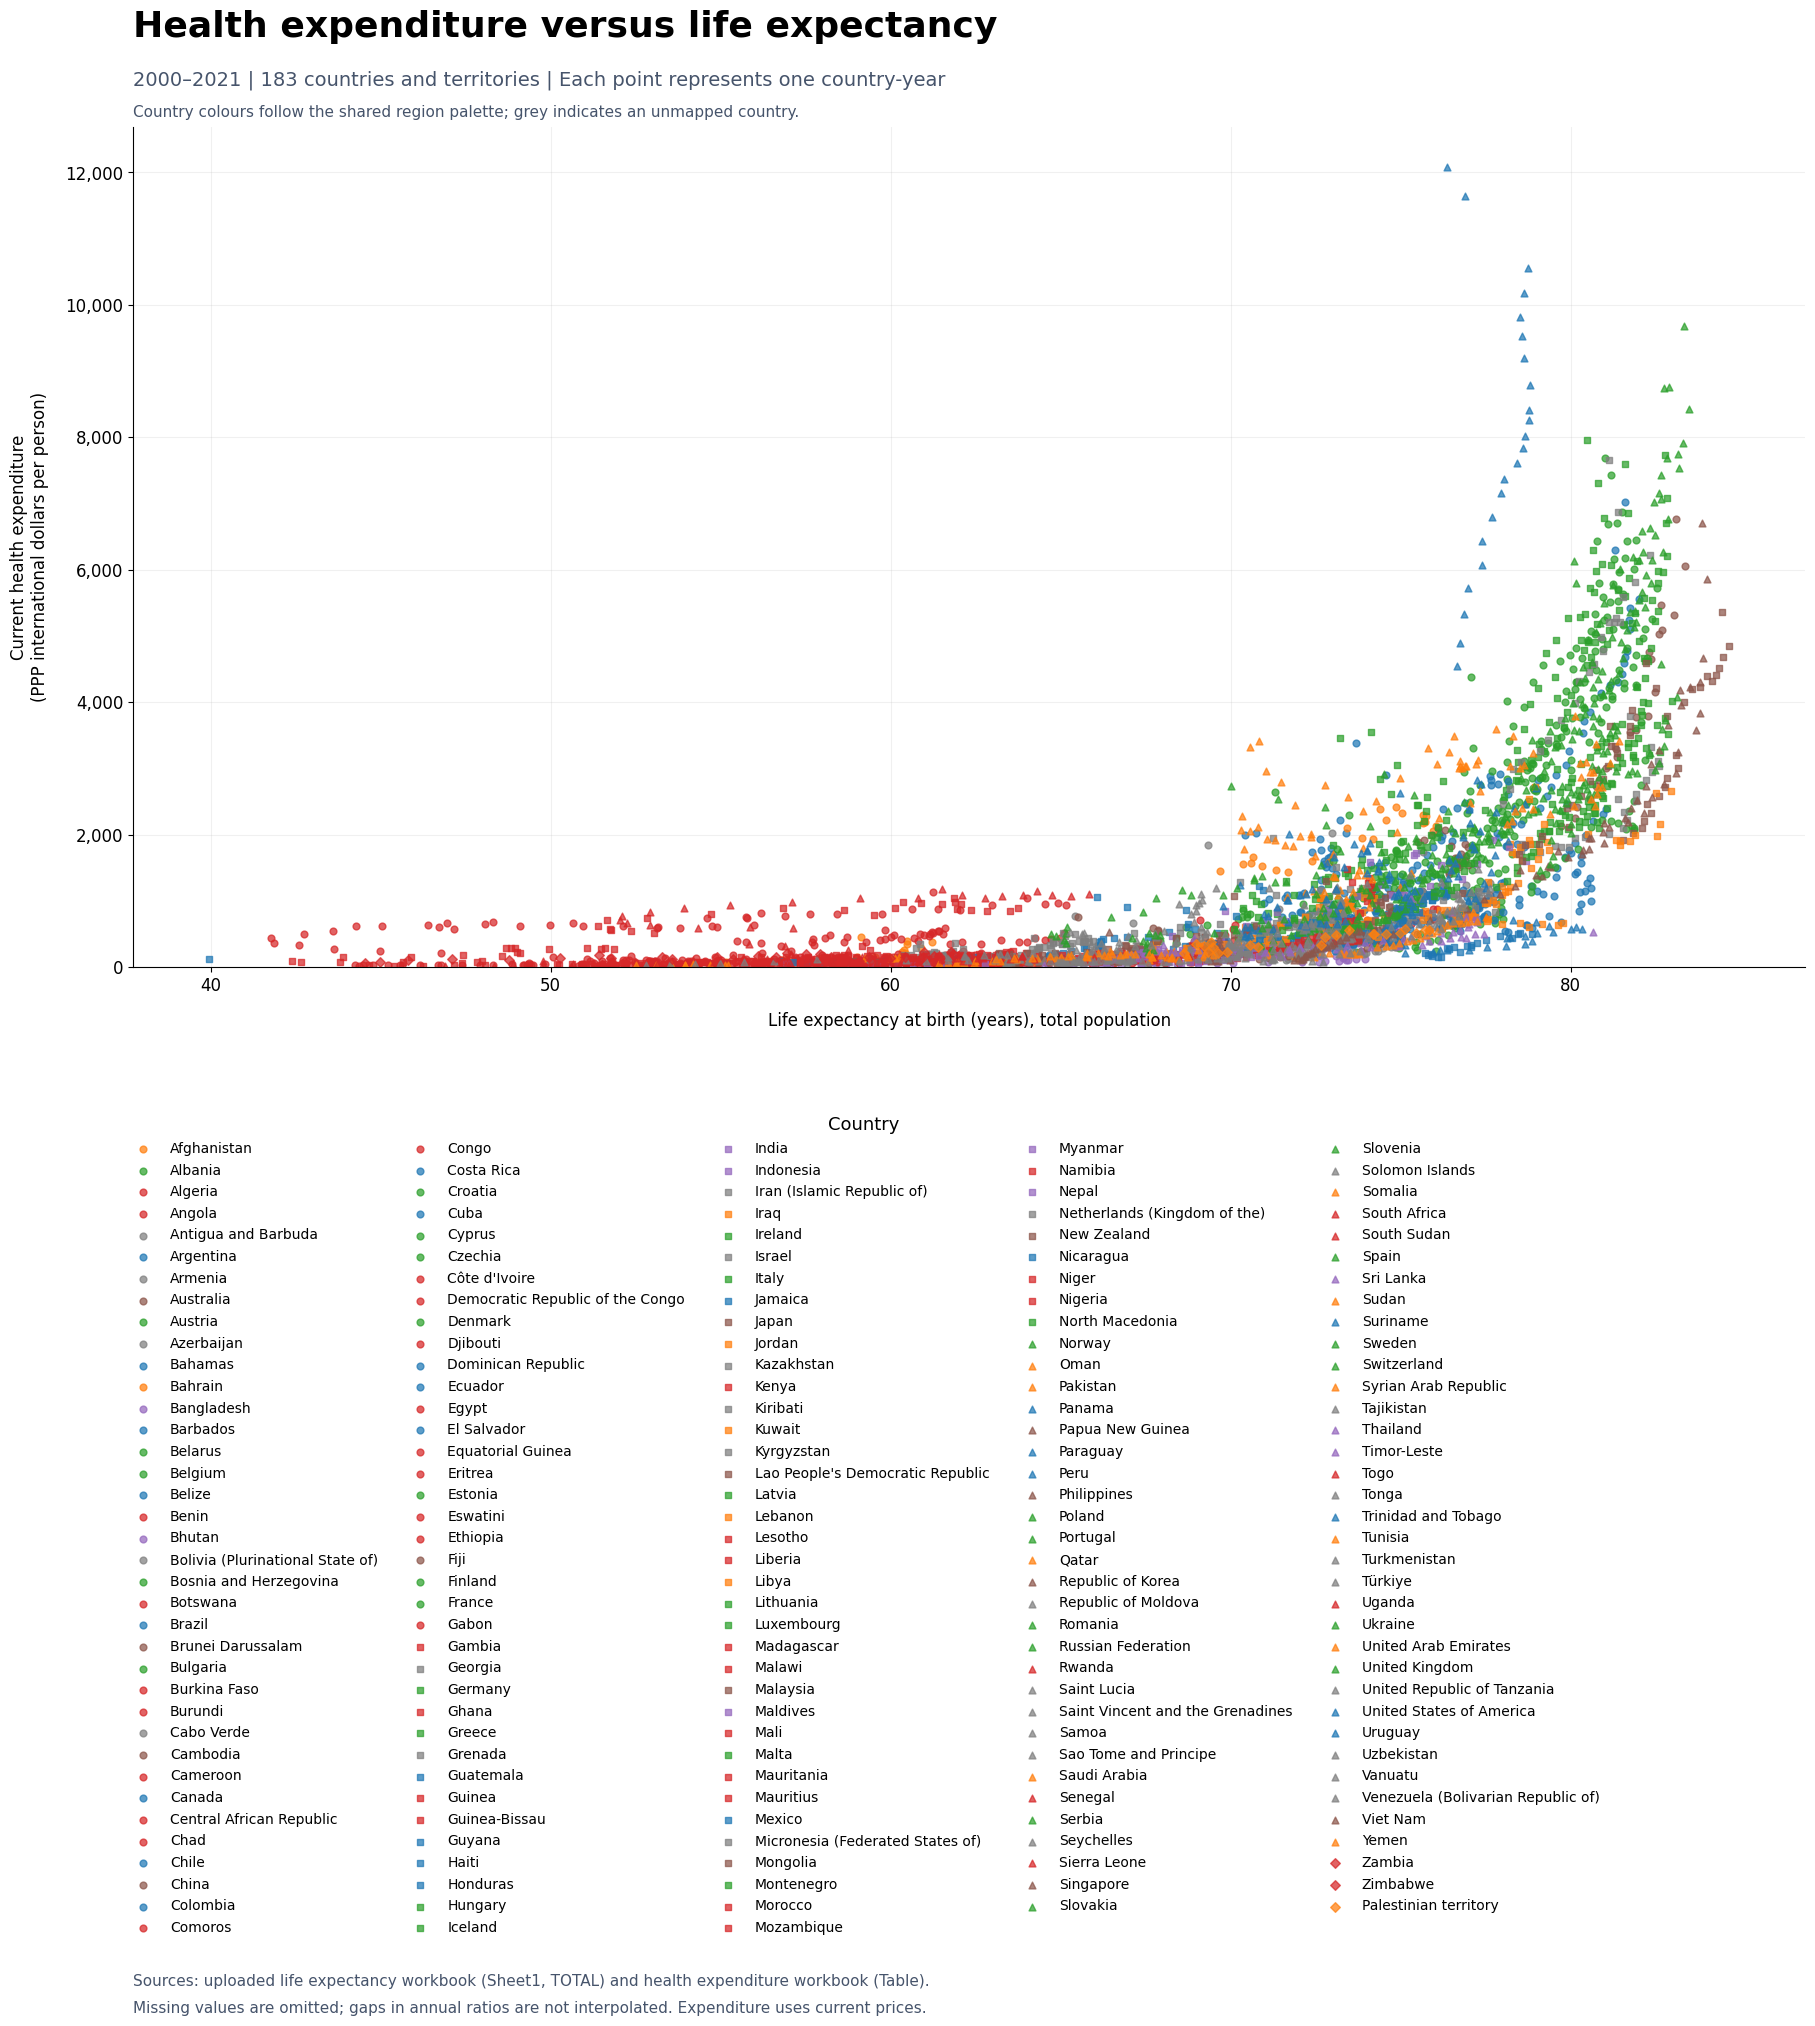

In [4]:
scatter_path = create_plot('scatter')


## 2. Life expectancy per health expenditure over time

Each line represents one country or territory. The y-axis is logarithmic; equal vertical distances indicate equal proportional changes.


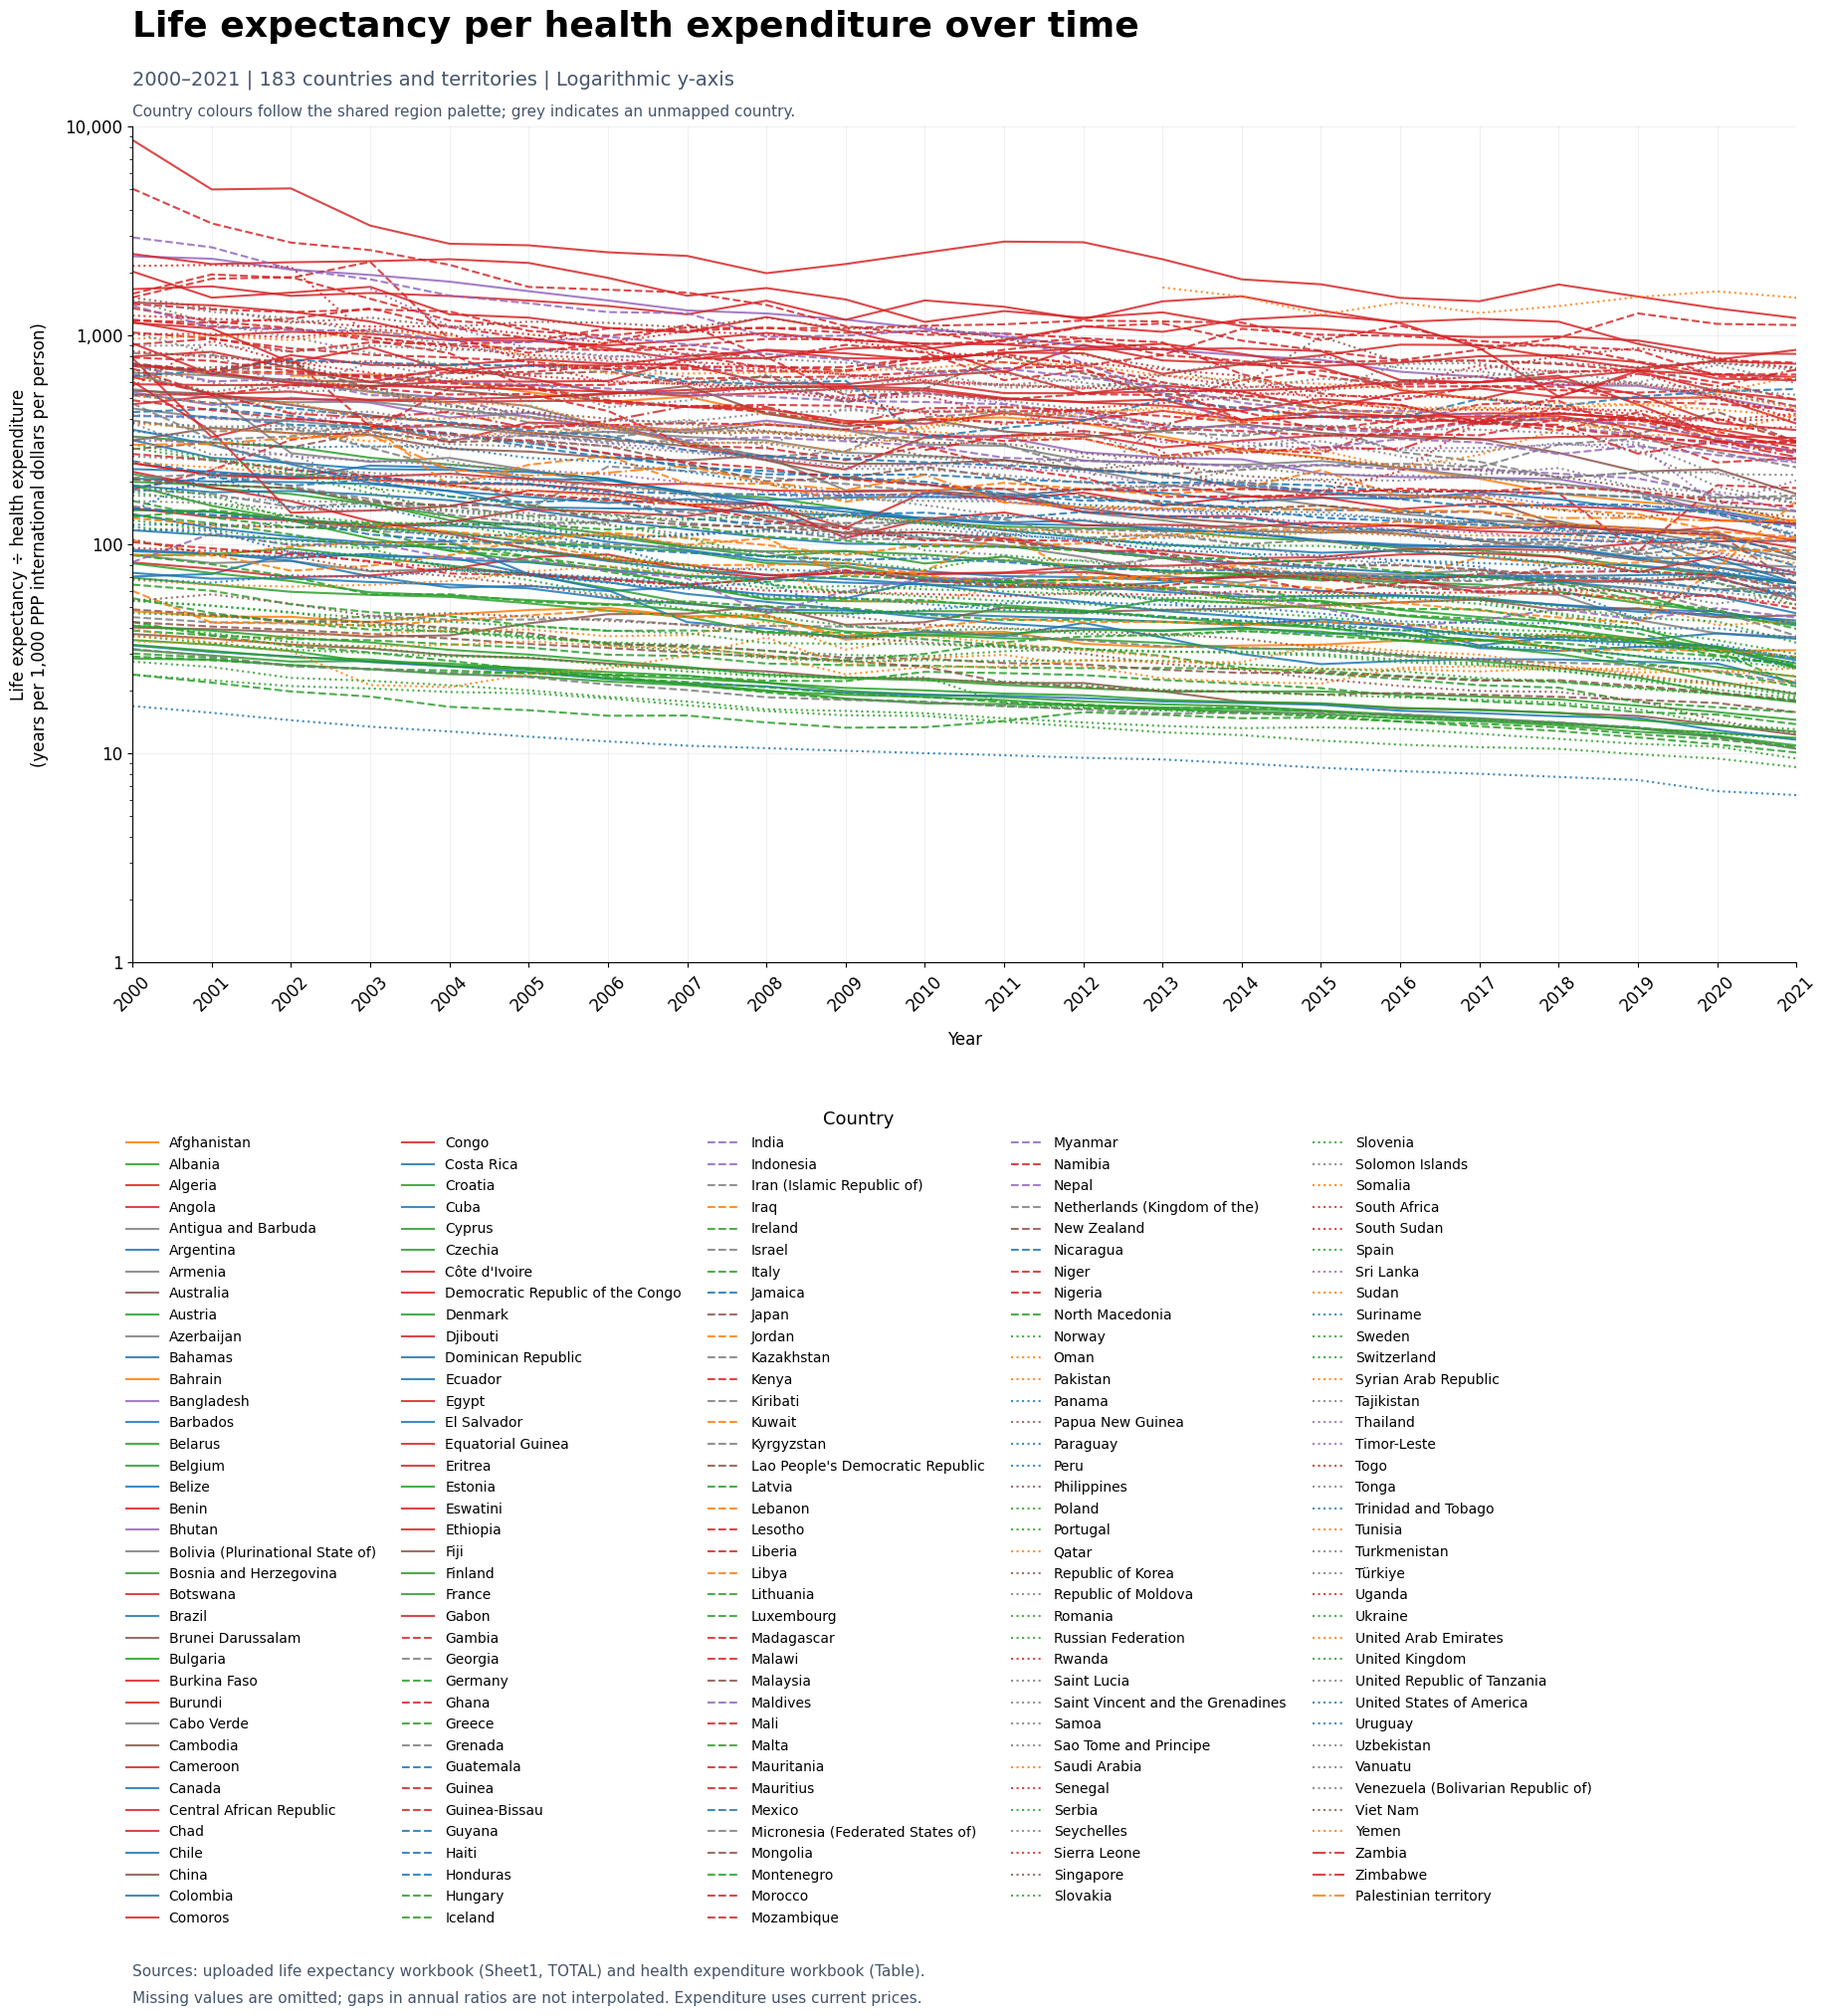

In [5]:
ratio_path = create_plot('ratio')


## Download both plots

Run this optional cell to download a ZIP containing both PNG files.


In [6]:
'''import zipfile
with zipfile.ZipFile("life_expectancy_health_expenditure_plots.zip", "w", zipfile.ZIP_DEFLATED) as archive:
    for path in [scatter_path, ratio_path]:
        archive.write(path, arcname=path.name)
files.download("life_expectancy_health_expenditure_plots.zip")'''


'import zipfile\nwith zipfile.ZipFile("life_expectancy_health_expenditure_plots.zip", "w", zipfile.ZIP_DEFLATED) as archive:\n    for path in [scatter_path, ratio_path]:\n        archive.write(path, arcname=path.name)\nfiles.download("life_expectancy_health_expenditure_plots.zip")'

In [7]:
#Spearman and Pearson Tests
corr_df = df[[life_col, expenditure_col]].dropna()

r_p, p_p = pearsonr(
    corr_df[expenditure_col],
    corr_df[life_col]
)

r_s, p_s = spearmanr(
    corr_df[expenditure_col],
    corr_df[life_col]
)

print(f"Pearson r = {r_p:.4f}")
print(f"Pearson p = {p_p:.4e}")
print(f"Spearman rho = {r_s:.4f}")
print(f"Spearman p = {p_s:.4e}")

model_df = df[[life_col, expenditure_col]].dropna()

# Linear
X1 = sm.add_constant(model_df[expenditure_col])
linear_model = sm.OLS(model_df[life_col], X1).fit()

# Log
X2 = sm.add_constant(np.log(model_df[expenditure_col]))
log_model = sm.OLS(model_df[life_col], X2).fit()

print("Linear R²:", linear_model.rsquared)
print("Log R²:", log_model.rsquared)


Pearson r = 0.6306
Pearson p = 0.0000e+00
Spearman rho = 0.8617
Spearman p = 0.0000e+00
Linear R²: 0.3976183398310804
Log R²: 0.6682485226654283


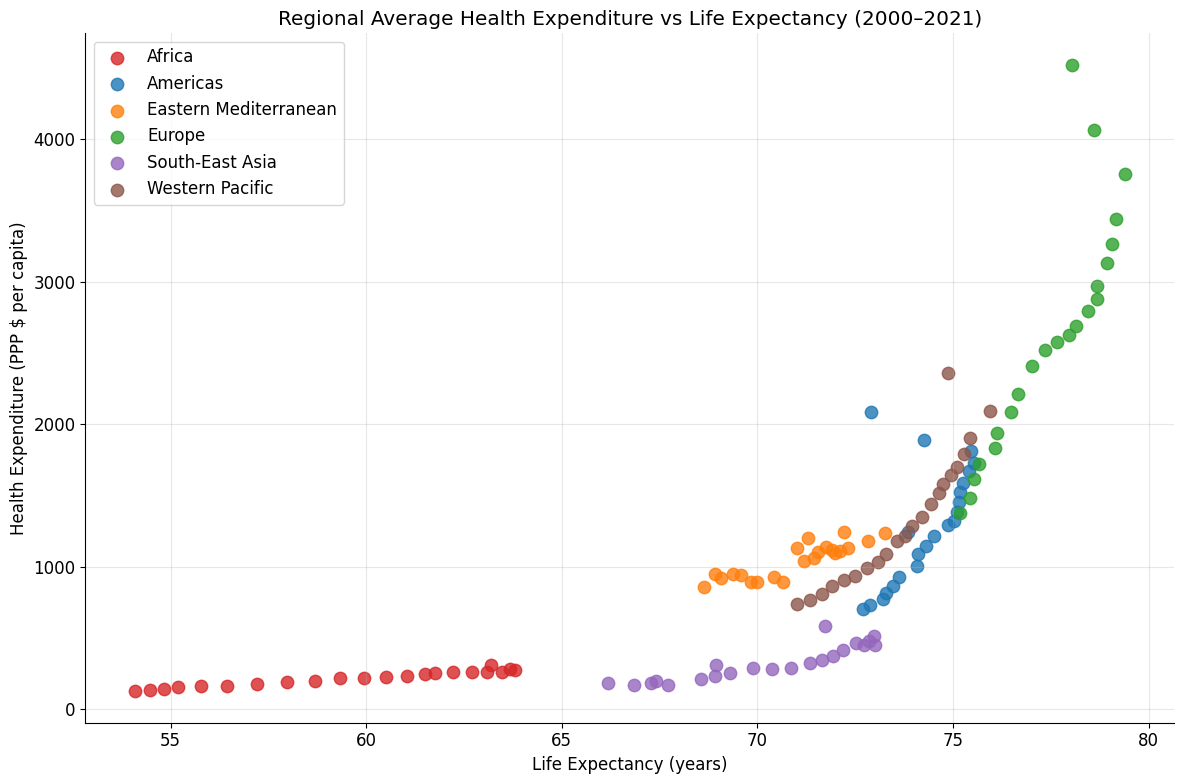

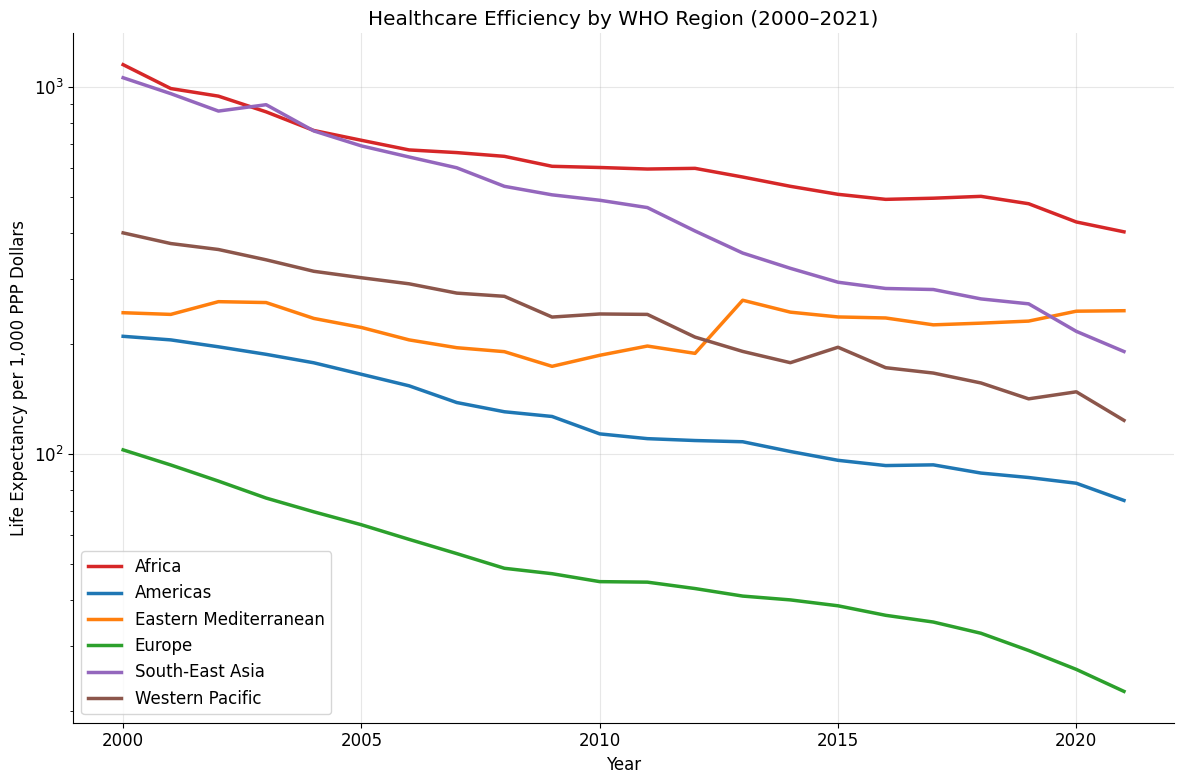

In [8]:
# ==========================
# WHO REGION ANALYSIS PLOTS
# ==========================

life_col = "Life expectancy at birth (years), total population"
expenditure_col = "Current health expenditure (PPP international dollars per capita)"
ratio_col = "Life expectancy / expenditure (years per 1000 PPP international dollars per capita)"

# WHO regional assignments
# Region assignments and shared colours are defined in the plot styling cell.

# Create region column
df["Region"] = df["Country"].map(region_map)

# Remove countries not mapped
regional_df = df.dropna(subset=["Region"]).copy()

# Calculate yearly regional means
regional_avg = (
    regional_df
    .groupby(["Region","Year"])
    [[life_col, expenditure_col, ratio_col]]
    .mean()
    .reset_index()
)

# Use the shared region_colors palette.

# -------------------------
# Scatter Plot
# -------------------------
plt.figure(figsize=(12,8))

for region in regional_avg["Region"].unique():
    temp = regional_avg[regional_avg["Region"] == region]

    plt.scatter(
        temp[life_col],
        temp[expenditure_col],
        s=80,
        alpha=0.8,
        color=region_colors[region],
        label=region
    )

plt.xlabel("Life Expectancy (years)")
plt.ylabel("Health Expenditure (PPP $ per capita)")
plt.title("Regional Average Health Expenditure vs Life Expectancy (2000–2021)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# -------------------------
# Ratio Time Series Plot
# -------------------------
plt.figure(figsize=(12,8))

for region in regional_avg["Region"].unique():
    temp = regional_avg[regional_avg["Region"] == region]

    plt.plot(
        temp["Year"],
        temp[ratio_col],
        linewidth=2.5,
        color=region_colors[region],
        label=region
    )

plt.yscale("log")
plt.xlabel("Year")
plt.ylabel("Life Expectancy per 1,000 PPP Dollars")
plt.title("Healthcare Efficiency by WHO Region (2000–2021)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
#Creation of a clean dataframe for analysis using statistical models
model_df = df[
    [life_col, expenditure_col, "Country", "Region"]
].dropna()

model_df = model_df[
    model_df[expenditure_col] > 0
].copy()

In [10]:
#Model 1, Overall effect of healthcare spending - question being answered = is healthcare spending assoctaed with life expectancy globally
model1 = mixedlm(
    f'Q("{life_col}") ~ np.log(Q("{expenditure_col}"))',
    data=model_df,
    groups=model_df["Country"]
)

result1 = model1.fit()

print("="*60)
print("MODEL 1: GLOBAL SPENDING EFFECT")
print("="*60)
print(result1.summary())
#This model estimates life expectancy = beta0 + beta1 ln(healthcare spending) and accounts for repeated measurments within countires

#Model 2, Spending + regional diffrences - question being answered = after accounting for spending, do WHO regions differ?
model2 = mixedlm(
    f'Q("{life_col}") ~ np.log(Q("{expenditure_col}")) + C(Region)',
    data=model_df,
    groups=model_df["Country"]
)

result2 = model2.fit()

print("="*60)
print("MODEL 2: SPENDING + REGION")
print("="*60)
print(result2.summary())
#This model estemates life expectancy = beta0 + beta1 ln(healthcare spending) + beta2 Region
#This tests the effect of spending and whether regions differ in baseline life expectancy

#Model 3, spending x regional interaction - question being answered = Does healthcare spending have diffrent effects in diffrent regions?
model3 = mixedlm(
    f'Q("{life_col}") ~ np.log(Q("{expenditure_col}")) * C(Region)',
    data=model_df,
    groups=model_df["Country"]
)

result3 = model3.fit()

print("="*60)
print("MODEL 3: SPENDING × REGION INTERACTION")
print("="*60)
print(result3.summary())

#This model estimates beta0 + beta1 ln(healthcare spending) + beta2 Region + Beta 3 ((ln(spending x region)))
#This model answers if spending matters, do regions differ and do regions repsond diffrenty to increased spending
result1 = model1.fit(reml=False)
result2 = model2.fit(reml=False)
result3 = model3.fit(reml=False)
print(f"Model 1 AIC: {result1.aic:.2f}")
print(f"Model 2 AIC: {result2.aic:.2f}")
print(f"Model 3 AIC: {result3.aic:.2f}")

MODEL 1: GLOBAL SPENDING EFFECT
                                          Mixed Linear Model Regression Results
Model:                    MixedLM       Dependent Variable:       Q("Life expectancy at birth (years), total population")
No. Observations:         3329          Method:                   REML                                                   
No. Groups:               154           Scale:                    3.8898                                                 
Min. group size:          5             Log-Likelihood:           -7361.7503                                             
Max. group size:          22            Converged:                Yes                                                    
Mean group size:          21.6                                                                                           
-------------------------------------------------------------------------------------------------------------------------
                                  

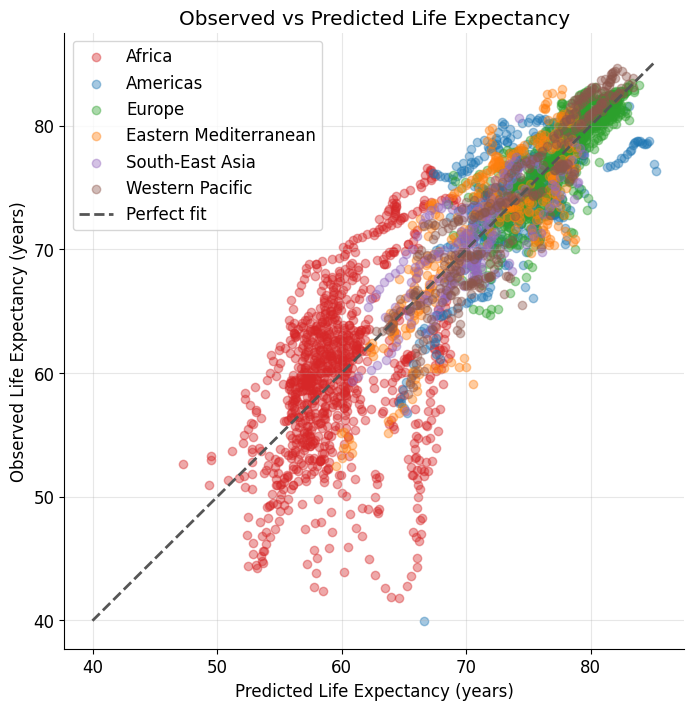

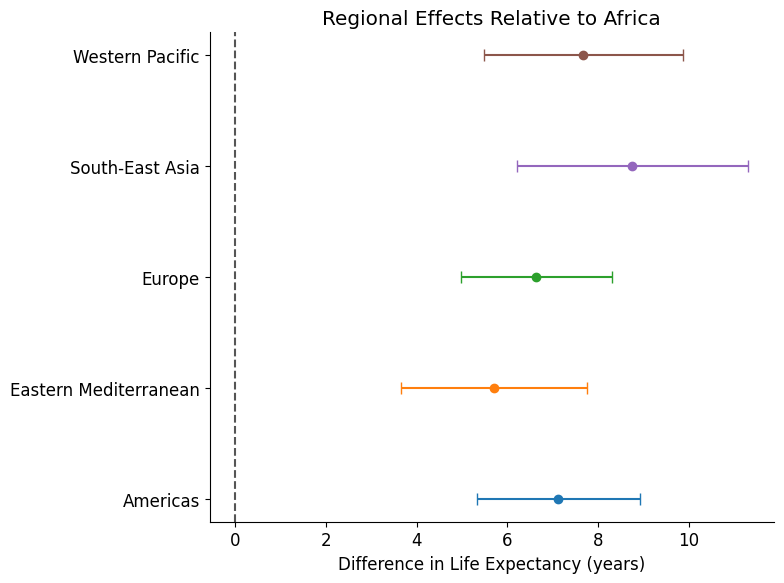

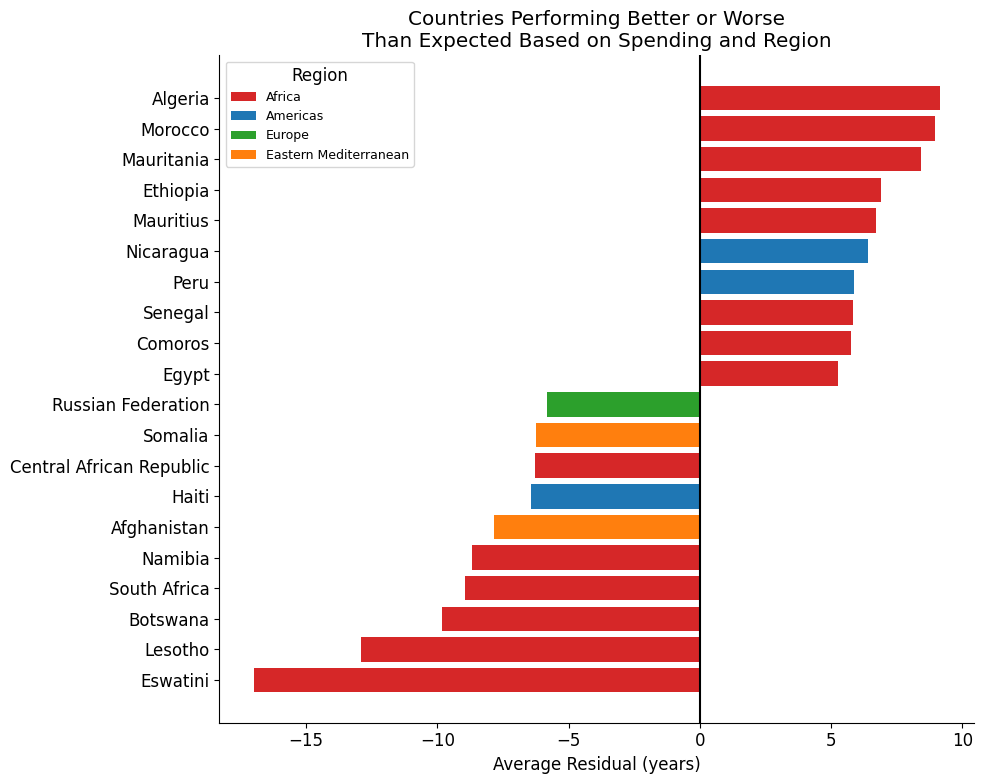

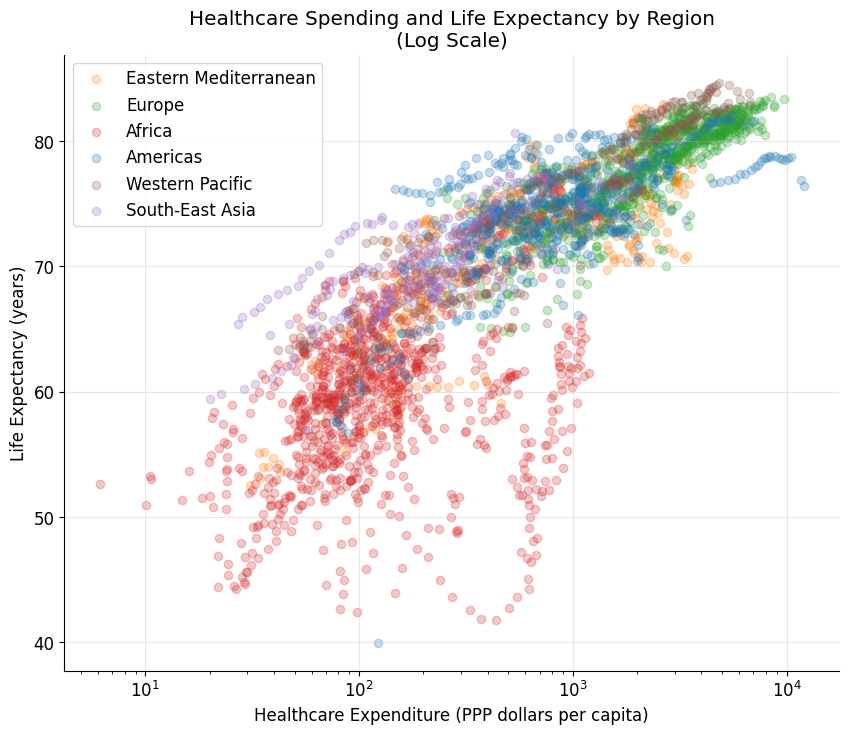

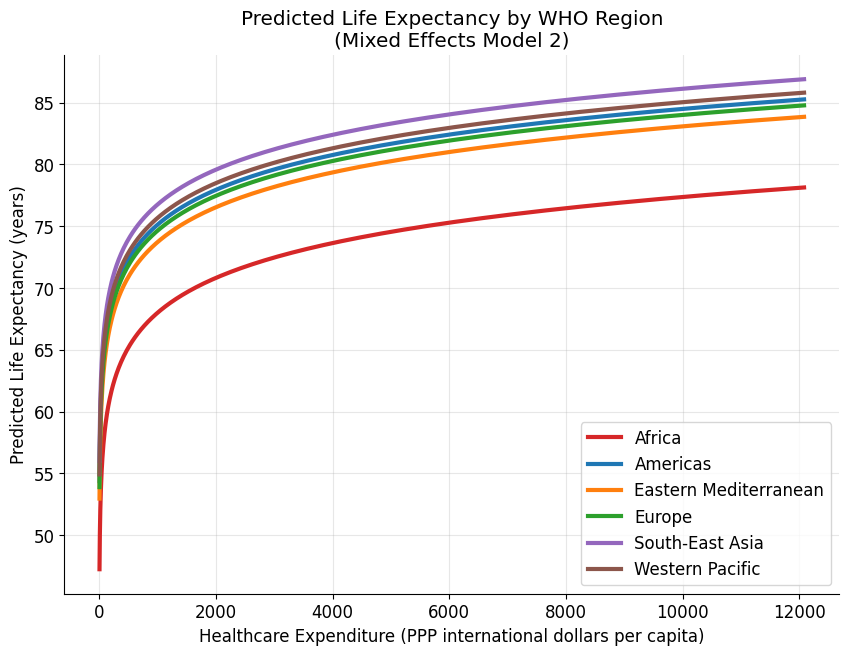

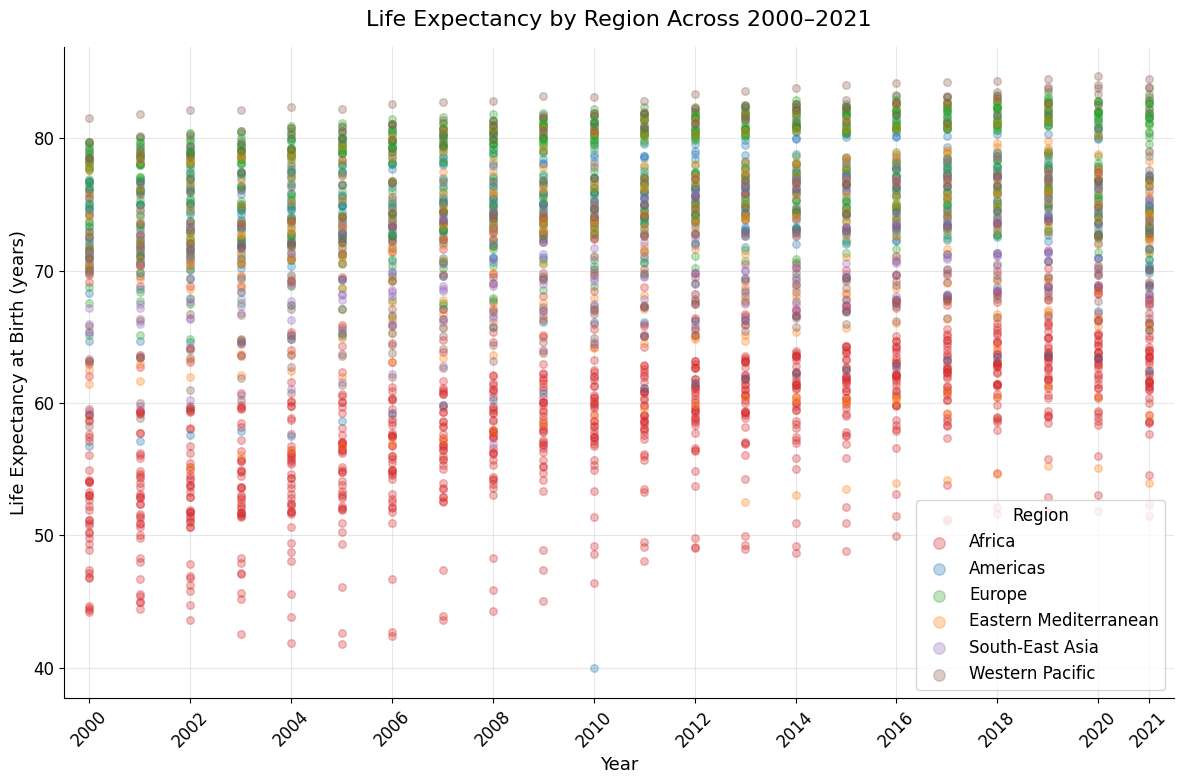

In [11]:
#Visualizations based on fit models
# Generate predictions
model_df["Predicted_LE"] = result2.predict(model_df)

plt.figure(figsize=(8,8))

for region in region_colors:
    temp = model_df.loc[model_df["Region"].eq(region)]
    if not temp.empty:
        plt.scatter(
            temp["Predicted_LE"], temp[life_col],
            alpha=0.4, color=region_colour(region), label=region
        )

# Perfect prediction line
min_val = min(
    model_df["Predicted_LE"].min(),
    model_df[life_col].min()
)

max_val = max(
    model_df["Predicted_LE"].max(),
    model_df[life_col].max()
)

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color='#555555', linestyle='--',
    linewidth=2,
    label='Perfect fit'
)

plt.xlabel("Predicted Life Expectancy (years)")
plt.ylabel("Observed Life Expectancy (years)")
plt.title("Observed vs Predicted Life Expectancy")
plt.legend()
plt.grid(alpha=0.3)

plt.show()



coef_names = [
    name for name in result2.params.index
    if "Region" in name
]

coef_values = [
    result2.params[name]
    for name in coef_names
]

conf = result2.conf_int()

lower = [
    conf.loc[name, 0]
    for name in coef_names
]

upper = [
    conf.loc[name, 1]
    for name in coef_names
]

plt.figure(figsize=(8,6))

coefficient_regions = [name.split("[T.", 1)[1].rstrip("]") for name in coef_names]
for position, region in enumerate(coefficient_regions):
    plt.errorbar(
        coef_values[position], position,
        xerr=[[coef_values[position] - lower[position]],
              [upper[position] - coef_values[position]]],
        fmt="o", color=region_colour(region), capsize=4
    )

plt.axvline(0, color='#555555', linestyle='--')

plt.yticks(range(len(coef_names)), coefficient_regions)

plt.xlabel("Difference in Life Expectancy (years)")
plt.title("Regional Effects Relative to Africa")

plt.tight_layout()
plt.show()



model_df["Residual"] = (
    model_df[life_col]
    - model_df["Predicted_LE"]
)

country_residuals = (
    model_df
    .groupby("Country")["Residual"]
    .mean()
    .sort_values()
)
top10 = country_residuals.tail(10)
bottom10 = country_residuals.head(10)

plot_data = pd.concat([bottom10, top10])

plt.figure(figsize=(10,8))

country_regions = model_df[["Country", "Region"]].drop_duplicates().set_index("Country")["Region"]
bar_regions = country_regions.reindex(plot_data.index).fillna("Unmapped")
colors = [region_colour(region) for region in bar_regions]

plt.barh(
    plot_data.index,
    plot_data.values,
    color=colors
)

add_region_legend(plt.gca(), bar_regions)
plt.axvline(0, color='black')

plt.xlabel("Average Residual (years)")
plt.title(
    "Countries Performing Better or Worse\n"
    "Than Expected Based on Spending and Region"
)

plt.tight_layout()
plt.show()


plt.figure(figsize=(10,8))

for region in model_df["Region"].unique():

    temp = model_df[
        model_df["Region"] == region
    ]

    plt.scatter(
        temp[expenditure_col],
        temp[life_col],
        alpha=0.25,
        color=region_colour(region),
        label=region
    )

plt.xscale("log")

plt.xlabel("Healthcare Expenditure (PPP dollars per capita)")
plt.ylabel("Life Expectancy (years)")
plt.title(
    "Healthcare Spending and Life Expectancy by Region\n"
    "(Log Scale)"
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()


# Create spending range
x_vals = np.logspace(
    np.log10(model_df[expenditure_col].min()),
    np.log10(model_df[expenditure_col].max()),
    200
)

regions = sorted(model_df["Region"].unique())

plt.figure(figsize=(10,7))

for region in regions:

    pred_df = pd.DataFrame({
        expenditure_col: x_vals,
        "Region": region,
        "Country": model_df["Country"].iloc[0]
    })

    y_pred = result2.predict(pred_df)

    plt.plot(
        x_vals,
        y_pred,
        linewidth=3,
        color=region_colour(region),
        label=region
    )

#plt.xscale("log")
plt.xlabel("Healthcare Expenditure (PPP international dollars per capita)")
plt.ylabel("Predicted Life Expectancy (years)")

plt.title(
    "Predicted Life Expectancy by WHO Region\n"
    "(Mixed Effects Model 2)"
)

plt.legend()
plt.grid(alpha=0.3)

# Life expectancy over time, coloured by region
plot_df = df[
    ["Country", "Year", "Region", life_col, expenditure_col]
].copy()

plot_df["Year"] = pd.to_numeric(
    plot_df["Year"], errors="coerce"
)

# Match the model's requirement for complete data and positive spending
plot_df = plot_df.dropna(
    subset=["Year", "Region", life_col, expenditure_col]
)

plot_df = plot_df.loc[
    plot_df["Year"].between(2000, 2021)
    & (plot_df[expenditure_col] > 0)
]

fig, ax = plt.subplots(figsize=(12, 8))

for region in region_colors:
    temp = plot_df.loc[plot_df["Region"].eq(region)]

    if not temp.empty:
        ax.scatter(
            temp["Year"],
            temp[life_col],
            s=30,
            alpha=0.3,
            color=region_colour(region),
            label=region
        )

ax.set_xlabel("Year", fontsize=13)
ax.set_ylabel("Life Expectancy at Birth (years)", fontsize=13)

ax.set_title(
    "Life Expectancy by Region Across 2000–2021",
    fontsize=16,
    pad=15
)

ax.set_xticks(list(range(2000, 2021, 2)) + [2021])
ax.tick_params(axis="x", rotation=45)
ax.set_xlim(1999.5, 2021.5)

ax.legend(title="Region", markerscale=1.5)
ax.grid(alpha=0.3)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

plt.show()

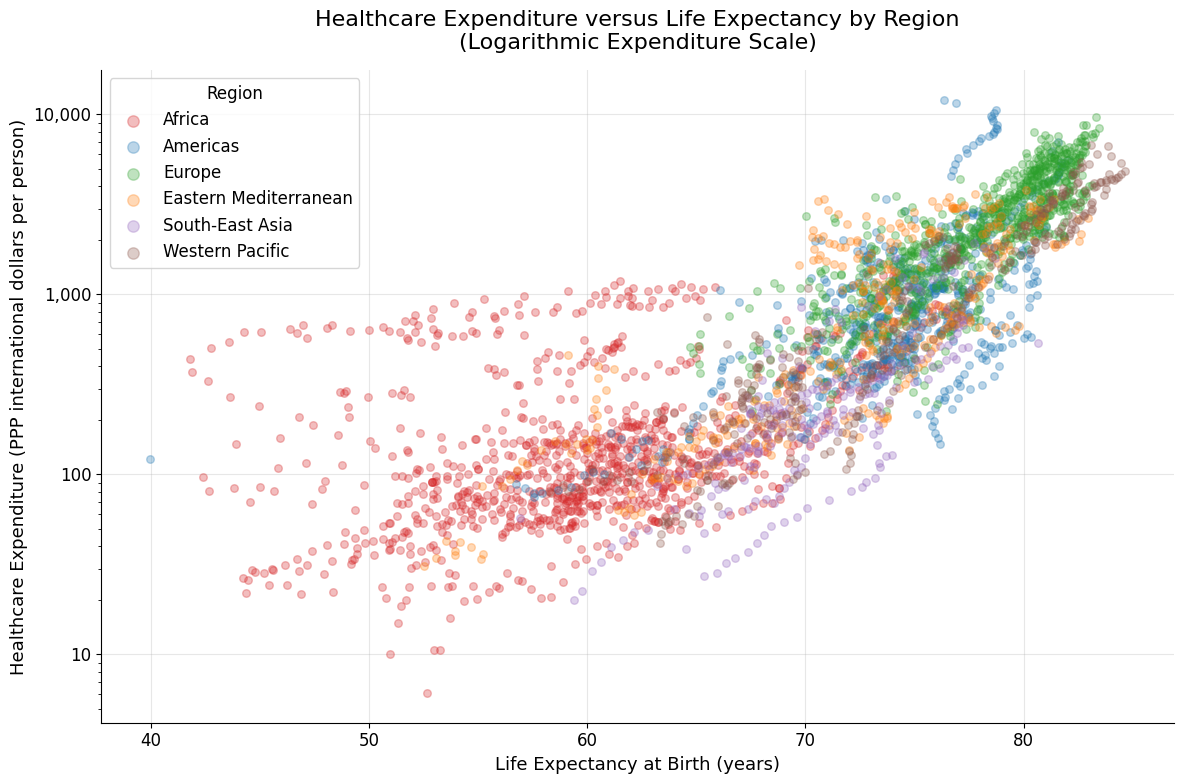

In [22]:
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(12, 8))

for region in region_colors:
    temp = model_df.loc[model_df["Region"].eq(region)]

    if not temp.empty:
        ax.scatter(
            temp[life_col],
            temp[expenditure_col],
            s=30,
            alpha=0.3,
            color=region_colour(region),
            label=region
        )

ax.set_yscale("log")

# Display spending as ordinary numbers rather than powers of ten
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f"{value:,.0f}")
)

ax.set_xlabel("Life Expectancy at Birth (years)", fontsize=13)
ax.set_ylabel(
    "Healthcare Expenditure (PPP international dollars per person)",
    fontsize=13
)

ax.set_title(
    "Healthcare Expenditure versus Life Expectancy by Region\n"
    "(Logarithmic Expenditure Scale)",
    fontsize=16,
    pad=15
)

ax.legend(title="Region", markerscale=1.5)
ax.grid(alpha=0.3)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

                       Life_2000  Life_2021   Spend_2000   Spend_2021  \
Region                                                                  
Africa                 54.084345  63.181381   124.379843   308.136268   
South-East Asia        66.171237  71.735606   182.422219   583.750546   
Eastern Mediterranean  68.628566  71.294983   860.197397  1204.427842   
Western Pacific        71.009867  74.881136   737.035460  2361.127904   
Europe                 75.169172  78.050748  1376.762540  4523.394619   
Americas               72.703806  72.894977   699.640627  2088.126344   

                       Life_Change  Spend_Change  Efficiency  
Region                                                        
Africa                    9.097037    183.756425    0.049506  
South-East Asia           5.564369    401.328328    0.013865  
Eastern Mediterranean     2.666418    344.230445    0.007746  
Western Pacific           3.871269   1624.092444    0.002384  
Europe                    2.881576   

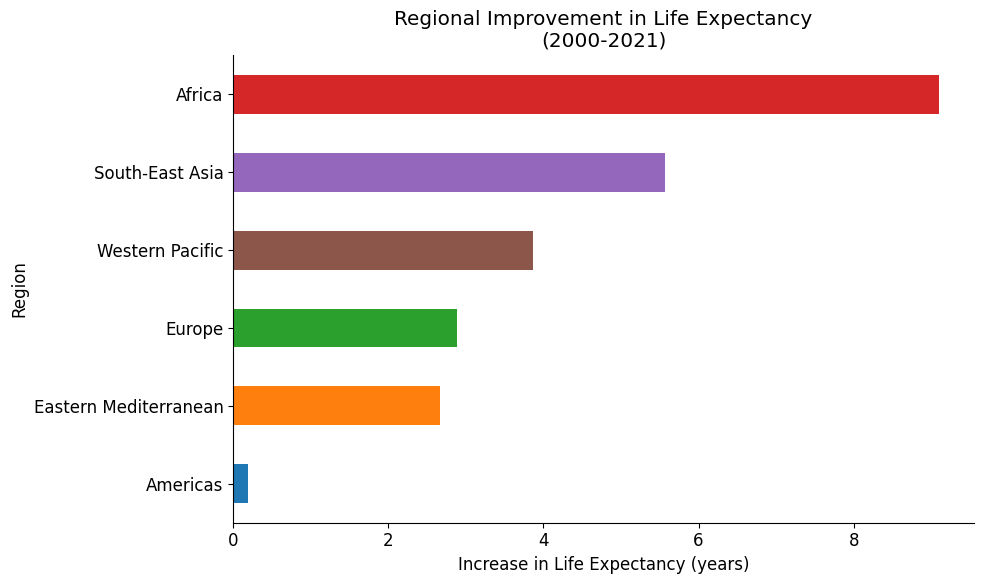

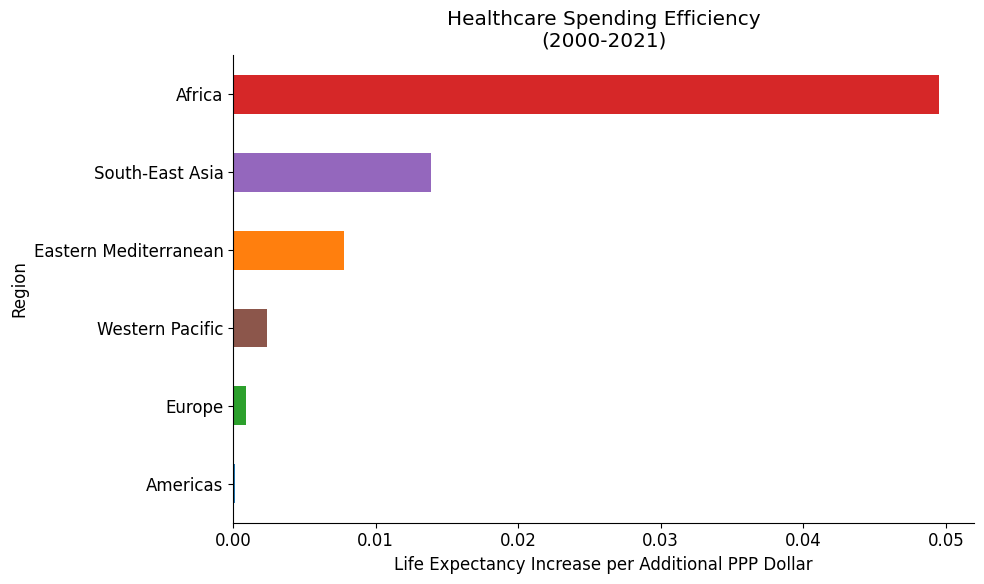

In [12]:
#Which regions improved the most between 2000 and 2021
regional_change = (
    df[df["Year"].isin([2000, 2021])]
    .groupby(["Region", "Year"])
    [[life_col, expenditure_col]]
    .mean()
    .reset_index()
)

pivot_life = regional_change.pivot(
    index="Region",
    columns="Year",
    values=life_col
)

pivot_spend = regional_change.pivot(
    index="Region",
    columns="Year",
    values=expenditure_col
)

change_df = pd.DataFrame({
    "Life_2000": pivot_life[2000],
    "Life_2021": pivot_life[2021],
    "Spend_2000": pivot_spend[2000],
    "Spend_2021": pivot_spend[2021]
})

change_df["Life_Change"] = (
    change_df["Life_2021"] -
    change_df["Life_2000"]
)

change_df["Spend_Change"] = (
    change_df["Spend_2021"] -
    change_df["Spend_2000"]
)

change_df["Efficiency"] = (
    change_df["Life_Change"] /
    change_df["Spend_Change"]
)

print(change_df.sort_values(
    "Efficiency",
    ascending=False
))


plt.figure(figsize=(10,6))

change_df["Life_Change"].sort_values().plot(
    kind="barh",
    color=[region_colour(r) for r in change_df["Life_Change"].sort_values().index]
)

plt.xlabel("Increase in Life Expectancy (years)")
plt.title(
    "Regional Improvement in Life Expectancy\n"
    "(2000-2021)"
)

plt.tight_layout()
plt.show()


plt.figure(figsize=(10,6))

change_df["Efficiency"].sort_values().plot(
    kind="barh",
    color=[region_colour(r) for r in change_df["Efficiency"].sort_values().index]
)

plt.xlabel(
    "Life Expectancy Increase per Additional PPP Dollar"
)

plt.title(
    "Healthcare Spending Efficiency\n"
    "(2000-2021)"
)

plt.tight_layout()
plt.show()



Africa
Slope = 2.733
R² = 0.151


Americas
Slope = 3.178
R² = 0.421


Eastern Mediterranean
Slope = 4.404
R² = 0.667


Europe
Slope = 4.182
R² = 0.707


South-East Asia
Slope = 3.409
R² = 0.621


Western Pacific
Slope = 4.716
R² = 0.871


/tmp/ipykernel_3712/3335841712.py:24: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  model.params[1],3
/tmp/ipykernel_3712/3335841712.py:24: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  model.params[1],3
/tmp/ipykernel_3712/3335841712.py:24: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  model.params[1],3
/tmp/ipykernel_3712/3335841712.py:24: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future vers

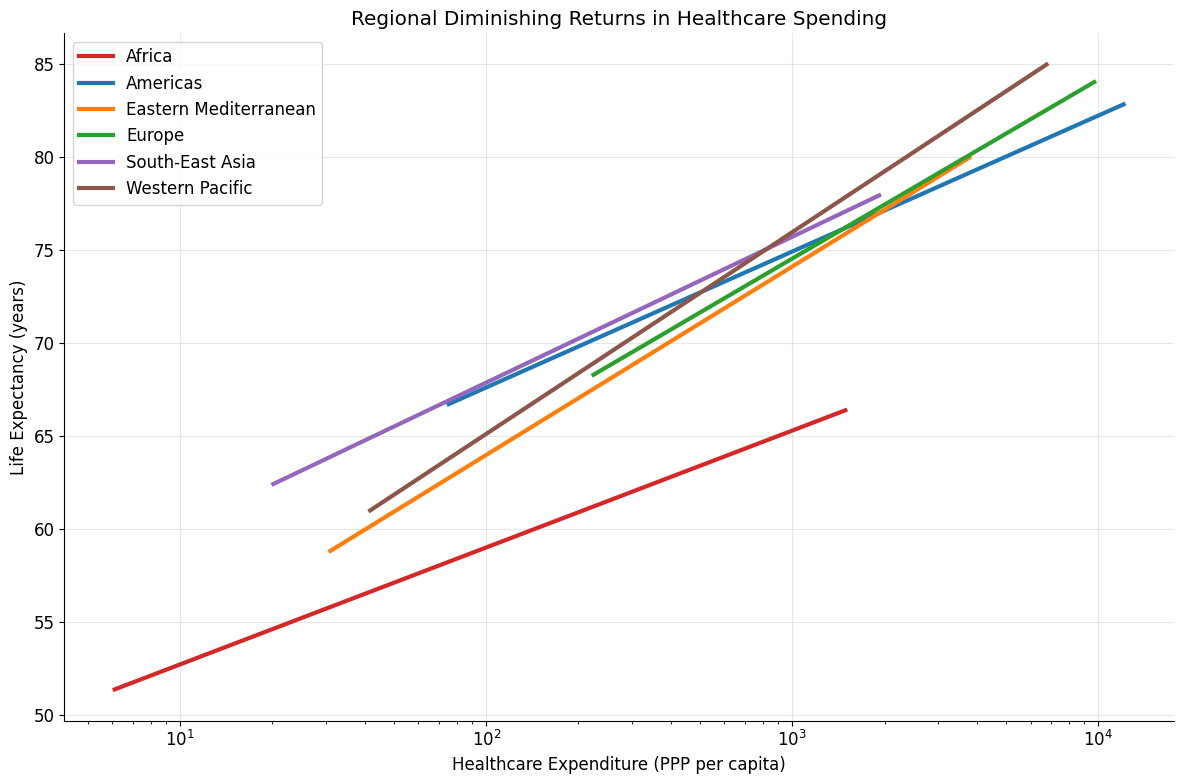

/tmp/ipykernel_3712/3335841712.py:87: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  m.params[1]


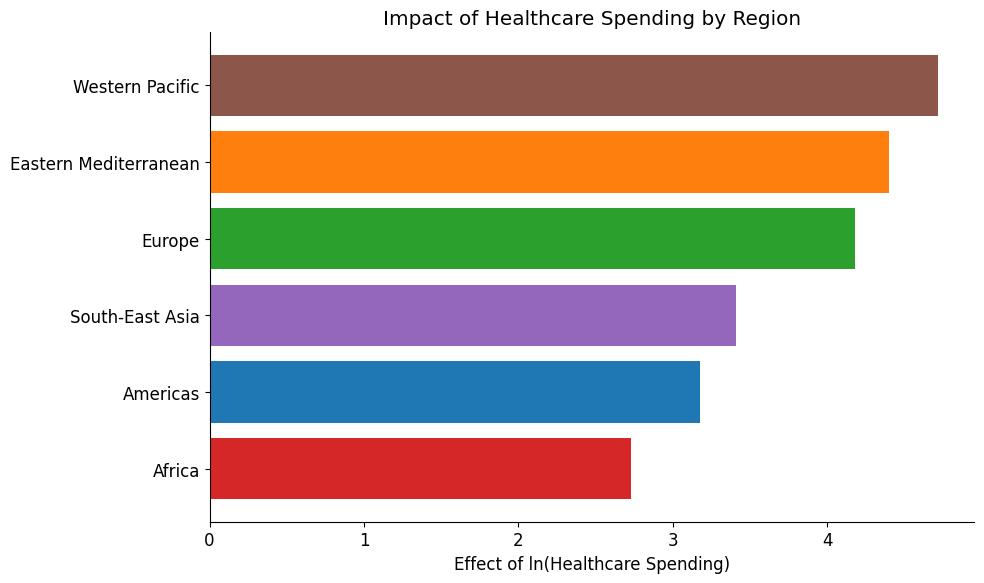

In [13]:
#Regional Deminishing Returns
import statsmodels.formula.api as smf

regional_models = {}

for region in sorted(
    model_df["Region"].unique()
):

    temp = model_df[
        model_df["Region"] == region
    ]

    model = smf.ols(
        f'Q("{life_col}") ~ np.log(Q("{expenditure_col}"))',
        data=temp
    ).fit()

    regional_models[region] = model

    print("\n")
    print(region)
    print("Slope =", round(
        model.params[1],3
    ))
    print("R² =", round(
        model.rsquared,3
    ))

plt.figure(figsize=(12,8))



for i, region in enumerate(
    sorted(model_df["Region"].unique())
):

    temp = model_df[
        model_df["Region"] == region
    ]

    x = np.linspace(
        temp[expenditure_col].min(),
        temp[expenditure_col].max(),
        200
    )

    y = (
        regional_models[region].params[0]
        +
        regional_models[region].params[1]
        * np.log(x)
    )

    plt.plot(
        x,
        y,
        linewidth=3,
        color=region_colour(region),
        label=region
    )

plt.xscale("log")

plt.xlabel(
    "Healthcare Expenditure (PPP per capita)"
)

plt.ylabel(
    "Life Expectancy (years)"
)

plt.title(
    "Regional Diminishing Returns in Healthcare Spending"
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


slope_df = pd.DataFrame({
    "Region": regional_models.keys(),
    "Slope": [
        m.params[1]
        for m in regional_models.values()
    ]
})

slope_df = slope_df.sort_values(
    "Slope"
)

plt.figure(figsize=(10,6))

plt.barh(
    slope_df["Region"],
    slope_df["Slope"],
    color=[region_colour(r) for r in slope_df["Region"]]
)

plt.xlabel(
    "Effect of ln(Healthcare Spending)"
)

plt.title(
    "Impact of Healthcare Spending by Region"
)

plt.tight_layout()
plt.show()

In [14]:
# ==========================================
# LOAD WHO DATASET
# ==========================================

import io
import pandas as pd

from google.colab import files

print("Upload WHS2026_DATADOWNLOAD.csv")

uploaded = files.upload()

csv_names = [
    f for f in uploaded
    if f.lower().endswith(".csv")
]

if len(csv_names) != 1:
    raise ValueError(
        "Upload exactly one CSV file."
    )

whs = pd.read_csv(
    io.BytesIO(uploaded[csv_names[0]])
)

print("\nDataset shape:")
print(whs.shape)

print("\nYears available:")
print(sorted(whs["Year"].unique()))

print("\nIndicators available:")
print(whs["IndicatorName"].nunique())

display(whs.head())

Upload WHS2026_DATADOWNLOAD.csv


Saving WHS2026_DATADOWNLOAD.csv to WHS2026_DATADOWNLOAD.csv

Dataset shape:
(8299, 9)

Years available:
['2016', '2016-2024', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025']

Indicators available:
50


,IndicatorName,IndicatorCode,Location,LocationCode,Year,Disaggregation,NumericValue,DisplayValue,Comments
0,Adolescent birth rate (per 1000 women aged 10-...,MDG_0000000003,Afghanistan,AFG,2021,AGEGROUP_YEARS10-14,18.000000,18,Afghanistan 2022-2023 Multiple Indicator Clust...
1,Adolescent birth rate (per 1000 women aged 10-...,MDG_0000000003,African Region,AFR,2025,AGEGROUP_YEARS10-14,2.878000,2.9,NaN
2,Adolescent birth rate (per 1000 women aged 10-...,MDG_0000000003,Albania,ALB,2022,AGEGROUP_YEARS10-14,0.210000,0.2,Registration Eurostat
3,Adolescent birth rate (per 1000 women aged 10-...,MDG_0000000003,Andorra,AND,2020,AGEGROUP_YEARS10-14,0.000000,0,Registration National Statistics & WPP2024
4,Adolescent birth rate (per 1000 women aged 10-...,MDG_0000000003,Antigua and Barbuda,ATG,2020,AGEGROUP_YEARS10-14,0.307977,0.3,Registration National Statistics & WPP2024


In [18]:
# ==========================================
# PREPARE DATA FOR THE MORTALITY HEATMAP
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

if "whs" not in globals():
    raise NameError(
        "Run the WHO CSV upload cell first to create whs."
    )

# Country ordering
country_order = [
    "Algeria", "Morocco", "Mauritania", "Ethiopia",
    "Mauritius", "Nicaragua", "Peru", "Senegal",
    "Comoros", "Egypt",
    "Russian Federation", "Somalia",
    "Central African Republic", "Haiti",
    "Afghanistan", "Namibia", "South Africa",
    "Botswana", "Lesotho", "Eswatini"
]

# WHO indicator names
indicator_names = [
    "Probability of dying from any of CVD, cancer, diabetes, CRD between age 30 and exact age 70 (%)",
    "Age-standardized mortality rate attributed to household and ambient air pollution (per 100 000 population)",
    "Mortality rate attributed to exposure to unsafe WASH services (per 100 000 population)",
    "Maternal mortality ratio (per 100 000 live births)",
    "Suicide mortality rate (per 100 000 population)"
]

# Column labels and units
axis_titles = [
    "Premature NCD mortality\nProbability, ages 30–70\n(%)",
    "Air pollution mortality\nAge-standardized deaths\nper 100,000 population",
    "Unsafe WASH mortality\nDeaths per 100,000\npopulation",
    "Maternal mortality\nMaternal deaths per\n100,000 live births",
    "Suicide mortality\nDeaths per 100,000\npopulation"
]

# Clean whitespace in indicator names
source = whs.copy()

source["_indicator"] = (
    source["IndicatorName"]
    .astype(str)
    .str.split()
    .str.join(" ")
)

source["_year"] = pd.to_numeric(
    source["Year"], errors="coerce"
)

source["_value"] = pd.to_numeric(
    source["NumericValue"], errors="coerce"
).replace([np.inf, -np.inf], np.nan)

heatmap_df = pd.DataFrame(
    np.nan,
    index=pd.Index(country_order, name="Country"),
    columns=indicator_names
)

year_df = heatmap_df.copy()

# Select the latest record for each country and indicator
for indicator in indicator_names:

    temp = source.loc[
        source["_indicator"].eq(indicator)
        & source["Location"].isin(country_order)
    ].dropna(subset=["_year"]).copy()

    if temp.empty:
        print(f"No matching records: {indicator}")
        continue

    latest_year = temp.groupby("Location")["_year"].transform("max")
    temp = temp.loc[temp["_year"].eq(latest_year)]

    temp = temp.drop_duplicates(
        subset=["Location", "_year", "_value"]
    )

    if temp["Location"].duplicated().any():
        raise ValueError(
            f"Multiple different estimates found for: {indicator}. "
            "Filter whs to the intended population or sex first."
        )

    temp = temp.set_index("Location")

    heatmap_df[indicator] = temp["_value"].reindex(country_order)
    year_df[indicator] = temp["_year"].reindex(country_order)

if not heatmap_df.notna().any().any():
    raise ValueError(
        "No matching mortality values were found. "
        "Check that whs contains the WHO World Health Statistics data."
    )

# Normalize colours separately within each indicator
normalized_df = heatmap_df.copy()

for column in heatmap_df.columns:
    valid = heatmap_df[column].dropna()

    if valid.empty:
        continue

    minimum = valid.min()
    maximum = valid.max()

    if maximum > minimum:
        normalized_df[column] = (
            heatmap_df[column] - minimum
        ) / (maximum - minimum)
    else:
        normalized_df.loc[valid.index, column] = 0.5

# Cell annotations: original values only
labels = pd.DataFrame(
    "",
    index=heatmap_df.index,
    columns=heatmap_df.columns
)

for column in heatmap_df.columns:
    labels[column] = heatmap_df[column].map(
        lambda value: f"{value:,.1f}" if pd.notna(value) else ""
    )

# X-axis labels: indicator, units, and year(s)
x_labels = []

for indicator, title in zip(indicator_names, axis_titles):

    years = sorted(
        year_df.loc[
            heatmap_df[indicator].notna(), indicator
        ].dropna().astype(int).unique()
    )

    if len(years) == 1:
        year_text = f"Year: {years[0]}"
    elif years:
        year_text = "Years: " + ", ".join(map(str, years))
    else:
        year_text = "No data"

    x_labels.append(f"{title}\n{year_text}")

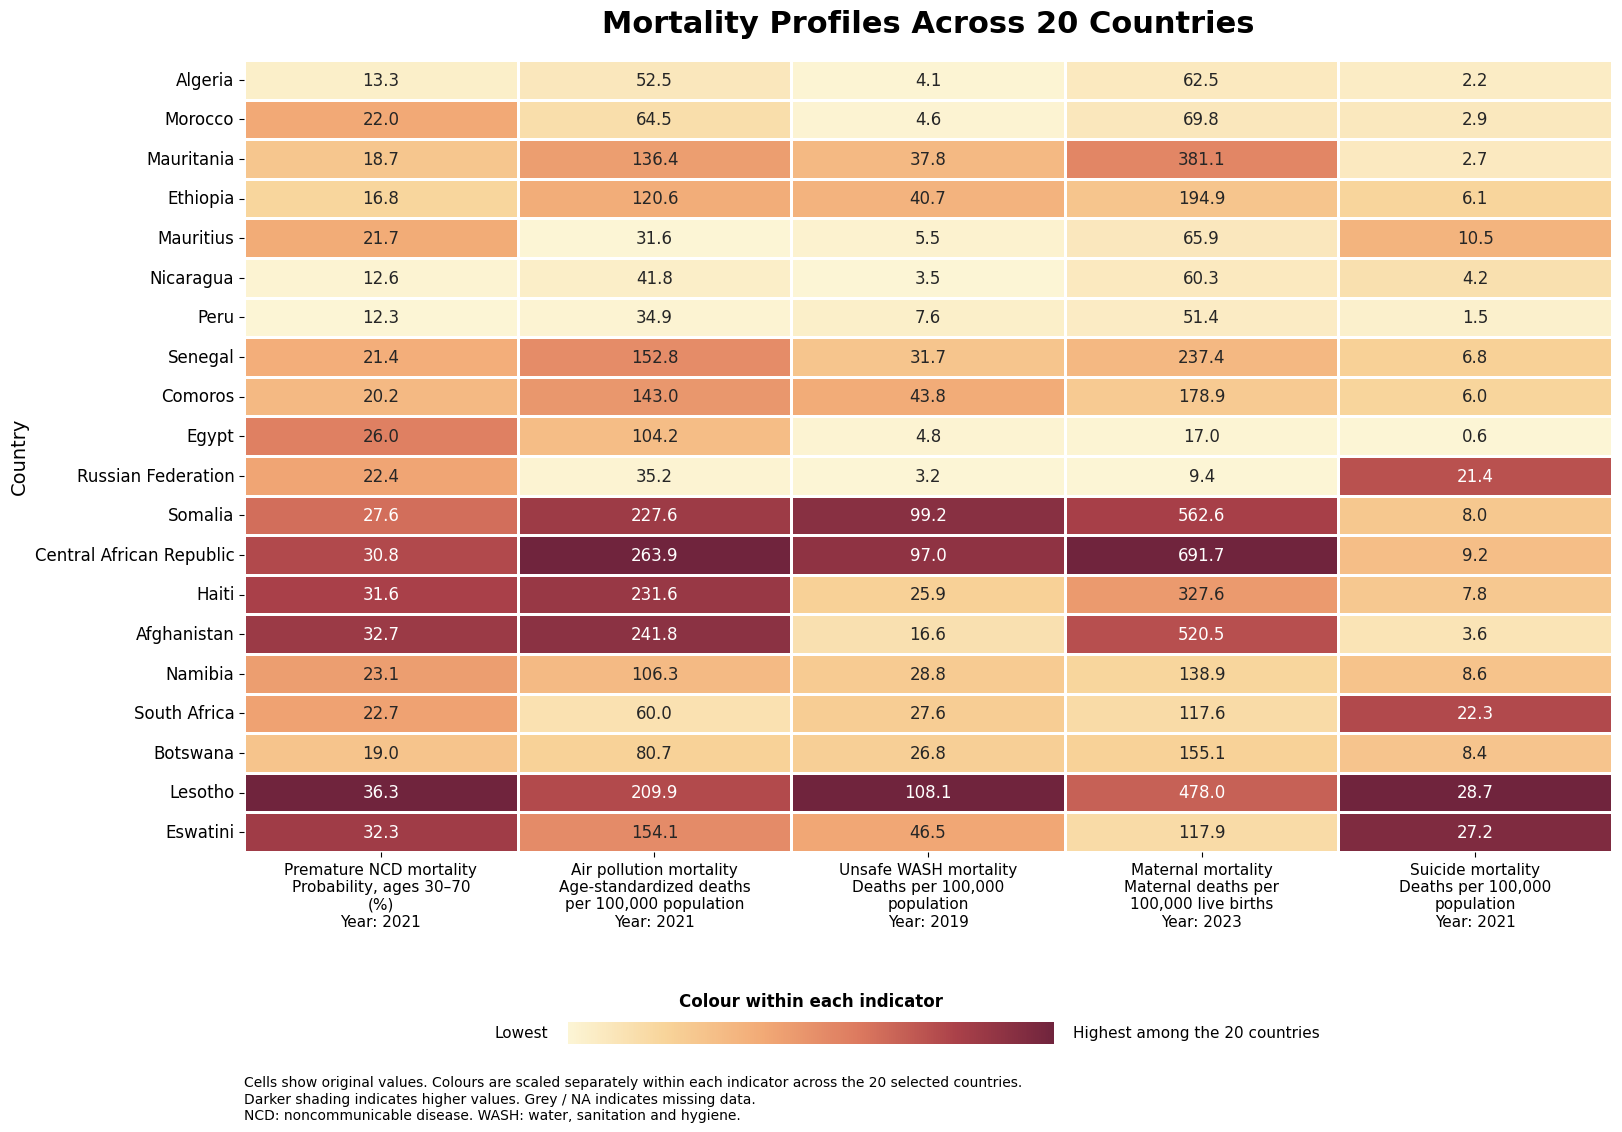

In [19]:
from matplotlib.colors import LinearSegmentedColormap
from pathlib import Path
import seaborn as sns

# Colour scale similar to your reference image
mortality_cmap = LinearSegmentedColormap.from_list(
    "mortality",
    [
        "#fcf5d5",  # Pale yellow: lowest
        "#f8d49a",
        "#f2aa76",  # Peach
        "#dc795f",
        "#aa4149",
        "#70243d"   # Burgundy: highest
    ],
    N=256
)

fig, ax = plt.subplots(figsize=(18, 12))

# Reserve space below for column labels and the colour legend
fig.subplots_adjust(
    left=0.22,
    right=0.98,
    top=0.91,
    bottom=0.25
)

# Horizontal colour bar position
cbar_ax = fig.add_axes([0.40, 0.09, 0.27, 0.018])

sns.heatmap(
    normalized_df,
    annot=labels,
    fmt="",
    cmap=mortality_cmap,
    vmin=0,
    vmax=1,
    linewidths=1,
    linecolor="white",
    mask=heatmap_df.isna(),
    annot_kws={"fontsize": 12},
    cbar=True,
    cbar_ax=cbar_ax,
    cbar_kws={
        "orientation": "horizontal",
        "ticks": []
    },
    ax=ax
)

# Improve number contrast on dark cells
for text in ax.texts:
    x, y = text.get_position()
    row, col = int(y), int(x)
    value = normalized_df.iloc[row, col]

    if pd.notna(value):
        red, green, blue, _ = mortality_cmap(value)
        brightness = (
            0.2126 * red
            + 0.7152 * green
            + 0.0722 * blue
        )
        text.set_color(
            "white" if brightness < 0.55 else "#262626"
        )

# Missing values
ax.set_facecolor("#dddddd")

for row, col in np.argwhere(heatmap_df.isna().to_numpy()):
    ax.text(
        col + 0.5,
        row + 0.5,
        "NA",
        ha="center",
        va="center",
        fontsize=11,
        color="#555555"
    )

ax.set_title(
    "Mortality Profiles Across 20 Countries",
    fontsize=22,
    weight="bold",
    pad=20
)

ax.set_xticklabels(x_labels, rotation=0, fontsize=11)
ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=0,
    fontsize=12
)
ax.set_xlabel("")
ax.set_ylabel("Country", fontsize=14)

# Colour legend labels
cbar_ax.set_title(
    "Colour within each indicator",
    fontsize=12,
    weight="bold",
    pad=12
)

cbar_ax.text(
    -0.04, 0.5, "Lowest",
    transform=cbar_ax.transAxes,
    ha="right", va="center", fontsize=11
)

cbar_ax.text(
    1.04, 0.5, "Highest among the 20 countries",
    transform=cbar_ax.transAxes,
    ha="left", va="center", fontsize=11
)


# Explanatory text at the bottom
fig.text(
    0.22, 0.025,
    "Cells show original values. Colours are scaled separately "
    "within each indicator across the 20 selected countries.\n"
    "Darker shading indicates higher values. "
    "Grey / NA indicates missing data.\n"
    "NCD: noncommunicable disease. "
    "WASH: water, sanitation and hygiene.",
    fontsize=10,
    ha="left",
    va="bottom"
)

output_dir = Path("plots")
output_dir.mkdir(exist_ok=True)

fig.savefig(
    output_dir / "mortality_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [20]:
# OPTIONAL: Automatically save all displayed figures
from pathlib import Path
import matplotlib.pyplot as plt

plot_directory = Path("plots")
plot_directory.mkdir(exist_ok=True)

# Avoid wrapping plt.show multiple times if this cell is rerun.
if not hasattr(plt.show, "_original_show"):
    original_show = plt.show

    def save_and_show(*args, **kwargs):
        for figure_number in plt.get_fignums():
            figure = plt.figure(figure_number)

            # Choose an unused filename.
            index = 1
            while (plot_directory / f"figure_{index:03d}.png").exists():
                index += 1

            figure.savefig(
                plot_directory / f"figure_{index:03d}.png",
                dpi=300,
                bbox_inches="tight"
            )

        return original_show(*args, **kwargs)

    save_and_show._original_show = original_show
    plt.show = save_and_show

In [21]:
# OPTIONAL: Download all saved figures as a ZIP
import zipfile
from pathlib import Path
from google.colab import files

plot_directory = Path("plots")
zip_path = Path("all_figures.zip")

figure_paths = sorted(
    path for path in plot_directory.rglob("*")
    if path.is_file()
    and path.suffix.lower() in {".png", ".jpg", ".jpeg", ".pdf", ".svg"}
)

if not figure_paths:
    print("No saved figures found. Run the plotting cells first.")
else:
    with zipfile.ZipFile(
        zip_path, "w", zipfile.ZIP_DEFLATED
    ) as archive:
        for path in figure_paths:
            archive.write(
                path,
                arcname=str(path.relative_to(plot_directory))
            )

    print(f"Downloading {len(figure_paths)} figure files.")
    files.download(str(zip_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>